# Homework 2.3 Solutions | Bivariate Relationships by Category

*Homework is designed to both test your knowledge and challenge you to apply familiar concepts in new applications. Answer clearly and completely. You are welcomed and encouraged to work in groups so long as your work is your own. Submit your figures and answers to [Gradescope](https://www.gradescope.com).*

In [1]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# File Path
file_path = 'https://econ-0150.tayweid.io/data/'

## Q1. Explore the Data

The dataset `amazon_book_sales.csv` lists Amazon's 50 bestselling books each year from 2009 to 2022. Prices are in US dollars, rounded to the nearest dollar. The column `Genre` marks each book as Fiction or Non Fiction.

In [2]:
# Load Data
books = pd.read_csv(file_path + 'amazon_book_sales.csv', index_col=0)
books.head()

,Name,Author,User Rating,Reviews,Price,Year,Genre,Median_Price
0,"Act Like a Lady, Think Like a Man: What Men Re...",Steve Harvey,4.6,5013,17,2009,Non Fiction,12.0
1,Arguing with Idiots: How to Stop Small Minds a...,Glenn Beck,4.6,798,5,2009,Non Fiction,12.0
2,"Breaking Dawn (The Twilight Saga, Book 4)",Stephenie Meyer,4.6,9769,13,2009,Fiction,12.0
3,Crazy Love: Overwhelmed by a Relentless God,Francis Chan,4.7,1542,14,2009,Non Fiction,12.0
4,Dead And Gone: A Sookie Stackhouse Novel (Sook...,Charlaine Harris,4.6,1541,4,2009,Fiction,12.0


a) How many unique books are in the dataset? *(hint: use `.unique()` to count a book only once even if it shows up in multiple years)*

In [3]:
len(books['Name'].unique())

441

There are 441 unique books. The dataset has 700 rows because many books appear in more than one year.

b) How many books made the bestseller list in more than one year? *(hint: `.value_counts()` counts how many times each `Name` appears)*

In [4]:
counts = books['Name'].value_counts()
(counts > 1).sum()

np.int64(122)

122 books made the list in more than one year. The most frequent repeats (10 years each) are the *Publication Manual of the American Psychological Association* and *The Very Hungry Caterpillar*.

## Q2. Price and Ratings by Genre

a) Create a scatterplot of `Price` (x-axis) vs `User Rating` (y-axis), colored by `Genre`.

Text(0.5, 1.0, 'Price vs User Rating by Genre')

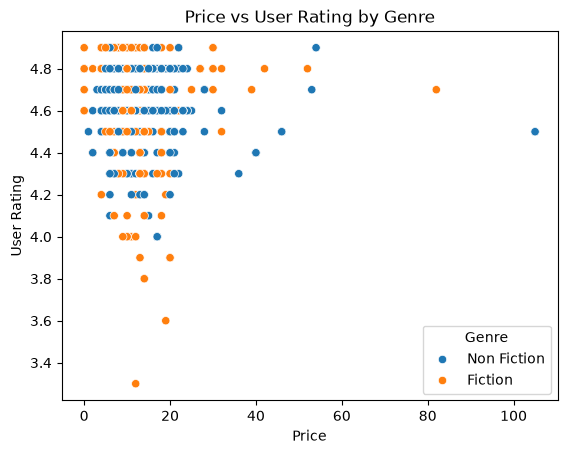

In [5]:
sns.scatterplot(data=books, x='Price', y='User Rating', hue='Genre')
plt.title('Price vs User Rating by Genre')

b) Is the relationship between price and rating positive, negative, or unclear?

Weakly negative. Higher-priced books tend to have slightly lower ratings, but the pattern is faint (correlation about −0.15) and most books cluster below $25.

c) Does the relationship look different for Fiction and Non Fiction?

No. The relationship looks about the same in both genres: Fiction and Non Fiction each have a weak negative relationship (correlation about −0.15 in each).

## Q3. Reviews and Ratings

a) Create a scatterplot of `Reviews` (x-axis) vs `User Rating` (y-axis) for all books.

Text(0.5, 1.0, 'Reviews vs User Rating')

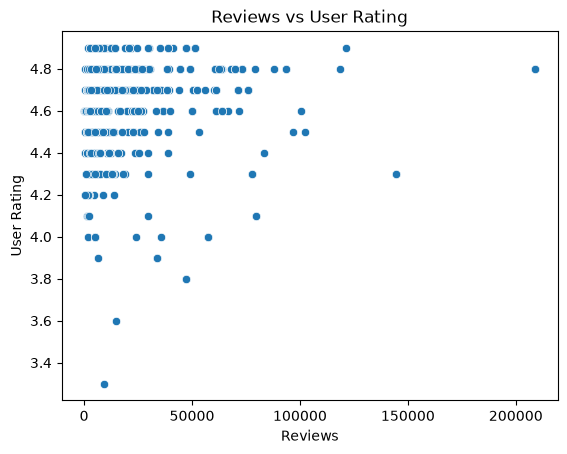

In [6]:
sns.scatterplot(data=books, x='Reviews', y='User Rating')
plt.title('Reviews vs User Rating')

b) Is there a relationship between reviews and ratings? If so, is it positive, negative, or unclear?

There is at most a weak positive relationship (correlation about 0.08). It is hard to see because `Reviews` is heavily right-skewed, which squeezes most books into the left side of the plot.

c) How might you use a transformation to improve this figure?

Take the log of `Reviews`. A log transformation spreads out the many books with few reviews and pulls in the handful with very many, so the relationship is easier to see.

## Q4. Does the Relationship Differ by Genre?

a) Create a scatterplot of `Reviews` vs `User Rating`, colored by `Genre`. Use any transformation you suggested in Q3.c).

Text(0.5, 1.0, 'Log Reviews vs User Rating by Genre')

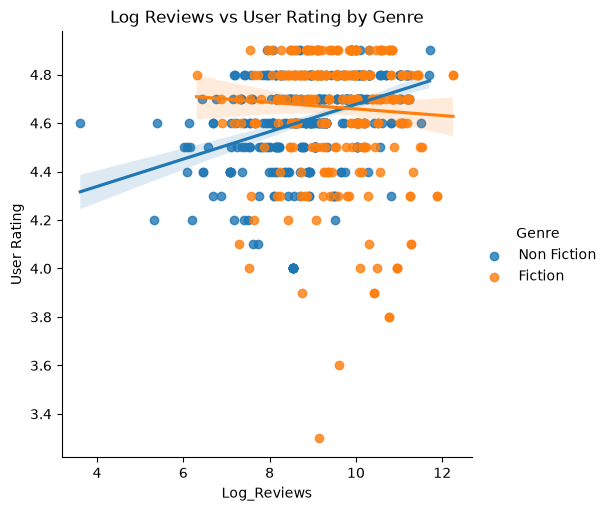

In [7]:
books['Log_Reviews'] = np.log(books['Reviews'])
sns.lmplot(data=books, x='Log_Reviews', y='User Rating', hue='Genre')
plt.title('Log Reviews vs User Rating by Genre')

b) Does the relationship between reviews and ratings differ between Fiction and Non Fiction? Describe the pattern.

Yes. For Non Fiction there is a clear positive relationship: books with more reviews tend to have higher ratings (correlation about 0.38). For Fiction there is essentially no relationship (correlation about −0.06): heavily reviewed novels are rated about the same as lightly reviewed ones. Fiction books also tend to have more reviews (median about 14,400 vs 7,900).

c) In one sentence, what hypothesis might explain the difference you observe?

Non Fiction readers may review a book mainly when it delivers on what it promised, so well-reviewed books are also well-liked, while popular novels draw many casual readers whose ratings vary regardless of how many reviews pile up.